<a href="https://colab.research.google.com/github/VictorManuelOrt/Biometric/blob/main/RBFBIOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CODIGO

Configuración: xor
Datos: 640 muestras, 4 clases
Entrenamiento: 480, Prueba: 160
Distribución clases: {np.int64(0): np.int64(122), np.int64(1): np.int64(123), np.int64(2): np.int64(121), np.int64(3): np.int64(114)}


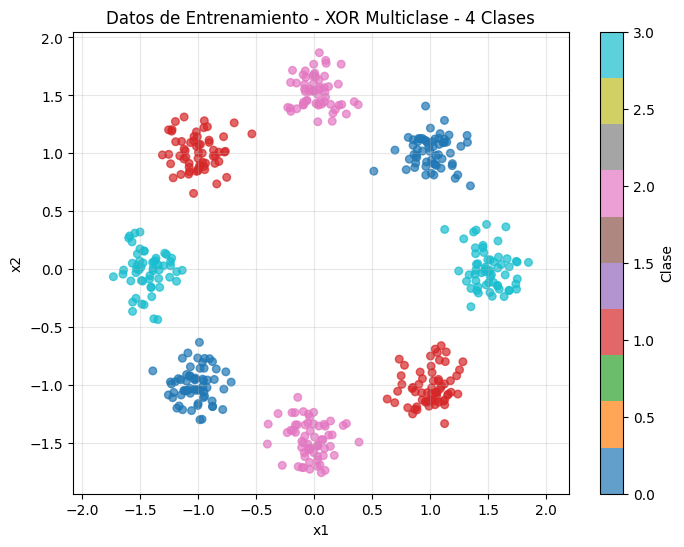

In [44]:
# METRIC LEARNING CON RBF - MÚLTIPLES CLASES
# C

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. GENERAR DATOS - MÚLTIPLES OPCIONES

np.random.seed(42)

def generar_circulos_concéntricos(n_por_clase=80, n_clases=4, ruido=0.1):
    """Genera círculos concéntricos con múltiples clases"""
    X = []
    y = []

    radios = np.linspace(0.5, 2.5, n_clases)

    for clase in range(n_clases):
        for _ in range(n_por_clase):
            angulo = np.random.uniform(0, 2*np.pi)
            radio = radios[clase] + np.random.randn() * ruido
            x = radio * np.cos(angulo)
            y_ = radio * np.sin(angulo)
            X.append([x, y_])
            y.append(clase)

    return np.array(X), np.array(y)

def generar_xor_multiclase(n_por_cluster=80):
    """Genera patrón XOR con 4 clases en las esquinas"""
    X = []
    y = []

    # Esquinas con clases diferentes
    esquinas = [
        (-1, -1, 0),  # Clase 0
        (1, 1, 0),    # Clase 0
        (-1, 1, 1),   # Clase 1
        (1, -1, 1),   # Clase 1
        (0, -1.5, 2), # Clase 2 (puntos extra)
        (0, 1.5, 2),  # Clase 2
        (-1.5, 0, 3), # Clase 3
        (1.5, 0, 3)   # Clase 3
    ]

    for cx, cy, cls in esquinas:
        for _ in range(n_por_cluster):
            x = cx + np.random.randn() * 0.15
            y_ = cy + np.random.randn() * 0.15
            X.append([x, y_])
            y.append(cls)

    return np.array(X), np.array(y)

def generar_espiral_multiclase(n_por_clase=100, n_clases=3, ruido=0.1):
    """Genera espirales con múltiples clases"""
    X = []
    y = []

    for clase in range(n_clases):
        for _ in range(n_por_clase):
            t = np.random.uniform(0, 4*np.pi)
            radio = 0.5 + t / (2*np.pi)
            angulo = t + clase * 2*np.pi / n_clases
            x = radio * np.cos(angulo) + np.random.randn() * ruido
            y_ = radio * np.sin(angulo) + np.random.randn() * ruido
            X.append([x, y_])
            y.append(clase)

    return np.array(X), np.array(y)

# 2. SELECCIONAR CONFIGURACIÓN

# Opciones: 'circulos', 'xor', 'espiral'
config = 'xor'  # CAMBIA AQUÍ PARA PROBAR OTRAS CONFIGURACIONES

if config == 'circulos':
    X, y = generar_circulos_concéntricos(n_por_clase=100, n_clases=4, ruido=0.1)
    titulo = "Círculos Concéntricos - 4 Clases"
elif config == 'xor':
    X, y = generar_xor_multiclase(n_por_cluster=80)
    titulo = "XOR Multiclase - 4 Clases"
else:  # espiral
    X, y = generar_espiral_multiclase(n_por_clase=100, n_clases=3, ruido=0.15)
    titulo = "Espirales - 3 Clases"

# Dividir en entrenamiento y prueba
indices = np.random.permutation(len(X))
split = int(0.75 * len(X))
X_train = X[indices[:split]]
y_train = y[indices[:split]]
X_test = X[indices[split:]]
y_test = y[indices[split:]]

n_clases = len(np.unique(y))
print(f"Configuración: {config}")
print(f"Datos: {len(X)} muestras, {n_clases} clases")
print(f"Entrenamiento: {len(X_train)}, Prueba: {len(X_test)}")
print(f"Distribución clases: {dict(zip(*np.unique(y_train, return_counts=True)))}")

# 3. VISUALIZAR DATOS ORIGINALES

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
plt.colorbar(scatter, label='Clase')
plt.title(f'Datos de Entrenamiento - {titulo}')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

# 4. PARÁMETROS DEL MODELO

K = 30          # Número de funciones RBF (más para más clases)
d = 2           # Dimensión del embedding (2D para visualizar)
alpha = 0.5     # Margen Triplet Loss
lr = 0.03       # Tasa de aprendizaje
epochs = 150    # Iteraciones

# 5. INICIALIZAR PARÁMETROS

# Centroides: K-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans.fit(X_train)
mu = kmeans.cluster_centers_.copy()  # (K, 2)

# Anchos: basados en distancia promedio
distancias = []
for i in range(K):
    for j in range(i+1, K):
        distancias.append(np.linalg.norm(mu[i] - mu[j]))
sigma = np.mean(distancias) / 2.0 if distancias else 0.5
gamma = np.ones(K) / (2.0 * sigma**2)
gamma = np.clip(gamma, 0.1, 5.0)  # (K,)

# Pesos y sesgo
W = np.random.randn(d, K) * 0.01   # (2, K)
b = np.zeros(d)                    # (2,)

# Historial
hist_loss = []

# 6. FUNCIONES AUXILIARES (SIMPLES)

def rbf_features(X, mu, gamma):
    """Calcula Φ(x) = exp(-γ_k * ||x - μ_k||²)"""
    n = len(X)
    Phi = np.zeros((n, K))
    for k in range(K):
        diff = X - mu[k]
        sq_dist = np.sum(diff**2, axis=1)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)
    return Phi

def forward(X, mu, gamma, W, b):
    """f_θ(x) = W * Φ(x) + b"""
    Phi = rbf_features(X, mu, gamma)
    return Phi @ W.T + b

def triplet_loss(emb, y):
    """Triplet Loss con Batch Hard Mining"""
    B = len(emb)
    loss = 0.0
    grad_emb = np.zeros_like(emb)

    # Matriz de distancias al cuadrado
    diff = emb[:, np.newaxis, :] - emb[np.newaxis, :, :]
    sq_dist = np.sum(diff**2, axis=2)

    for a in range(B):
        # Positivo más lejano
        same = np.where(y == y[a])[0]
        if len(same) < 2: continue
        p_idx = same[np.argmax(sq_dist[a, same])]
        d_ap = sq_dist[a, p_idx]

        # Negativo más cercano
        diff_cls = np.where(y != y[a])[0]
        if len(diff_cls) == 0: continue
        n_idx = diff_cls[np.argmin(sq_dist[a, diff_cls])]
        d_an = sq_dist[a, n_idx]

        # Pérdida
        l = max(0, d_ap - d_an + alpha)
        loss += l

        # Gradientes
        if l > 0:
            grad_emb[a] += 2 * (emb[n_idx] - emb[p_idx])
            grad_emb[p_idx] += 2 * (emb[p_idx] - emb[a])
            grad_emb[n_idx] += 2 * (emb[a] - emb[n_idx])

    return loss / B, grad_emb / B




Entrenando...
Época   0 | Loss: 0.5027
Época  10 | Loss: 0.5023
Época  20 | Loss: 0.5025
Época  30 | Loss: 0.5020
Época  40 | Loss: 0.5014
Época  50 | Loss: 0.5016
Época  60 | Loss: 0.5015
Época  70 | Loss: 0.5014
Época  80 | Loss: 0.5013
Época  90 | Loss: 0.5010
Época 100 | Loss: 0.5008
Época 110 | Loss: 0.5009
Época 120 | Loss: 0.5009
Época 130 | Loss: 0.5007
Época 140 | Loss: 0.5007
Entrenamiento completado!


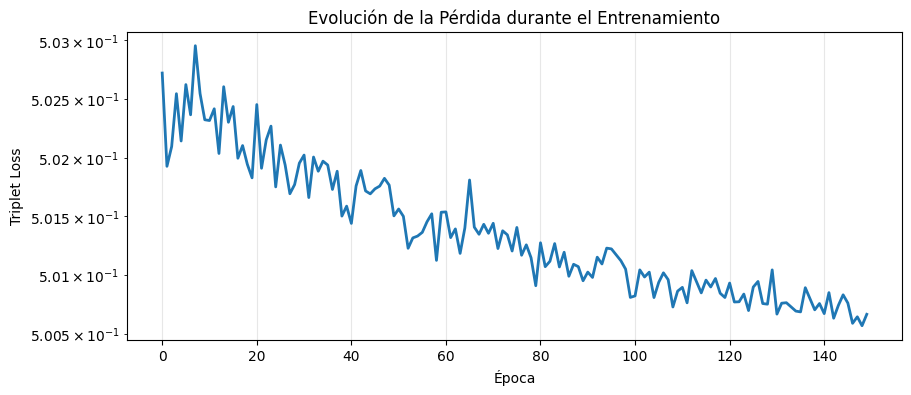

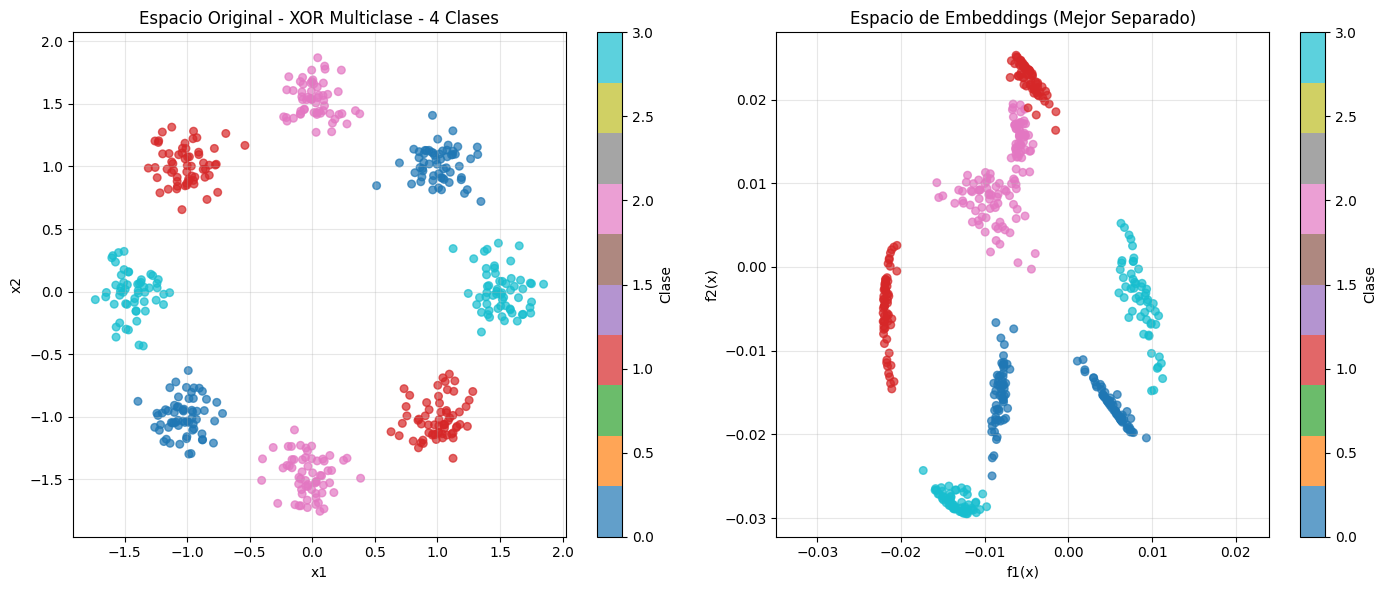

In [45]:
# 7. ENTRENAMIENTO ITERATIVO

print("\nEntrenando...")
print("=" * 60)

for epoch in range(epochs):
    # Barajar datos
    idx = np.random.permutation(len(X_train))
    batch_size = min(64, len(X_train))
    X_batch = X_train[idx[:batch_size]]
    y_batch = y_train[idx[:batch_size]]

    # Forward
    emb = forward(X_batch, mu, gamma, W, b)

    # Triplet Loss y gradientes
    loss, grad_emb = triplet_loss(emb, y_batch)

    if loss > 0:
        # Calcular gradientes de parámetros
        Phi = rbf_features(X_batch, mu, gamma)

        # Gradiente W: ∂L/∂W = Σ δ_i · Φ(x_i)^T
        grad_W = np.zeros_like(W)
        for i in range(len(X_batch)):
            grad_W += np.outer(grad_emb[i], Phi[i])
        grad_W /= len(X_batch)

        # Gradiente b
        grad_b = np.mean(grad_emb, axis=0)

        # Gradientes μ y γ
        grad_mu = np.zeros_like(mu)
        grad_gamma = np.zeros_like(gamma)

        for k in range(K):
            for i in range(len(X_batch)):
                delta_dot_Wk = grad_emb[i] @ W[:, k]
                phi_ki = Phi[i, k]
                diff = X_batch[i] - mu[k]

                # ∂L/∂μ_k
                grad_mu[k] += delta_dot_Wk * 2 * gamma[k] * diff * phi_ki

                # ∂L/∂γ_k
                grad_gamma[k] += delta_dot_Wk * (-np.sum(diff**2)) * phi_ki

            grad_mu[k] /= len(X_batch)
            grad_gamma[k] /= len(X_batch)

        # Actualizar parámetros
        W -= lr * grad_W
        b -= lr * grad_b
        mu -= lr * grad_mu
        gamma -= lr * grad_gamma
        gamma = np.maximum(gamma, 0.01)  # γ > 0

    hist_loss.append(loss)

    if epoch % 10 == 0:
        print(f"Época {epoch:3d} | Loss: {loss:.4f}")

print("=" * 60)
print("Entrenamiento completado!")

# 8. VISUALIZAR EVOLUCIÓN DE LA PÉRDIDA

plt.figure(figsize=(10, 4))
plt.plot(hist_loss, linewidth=2)
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la Pérdida durante el Entrenamiento')
plt.grid(True, alpha=0.3)
plt.yscale('log' if min(hist_loss) > 0 else 'linear')
plt.show()

# 9. OBTENER EMBEDDINGS

emb_train = forward(X_train, mu, gamma, W, b)
emb_test = forward(X_test, mu, gamma, W, b)

# 10. VISUALIZAR EMBEDDINGS

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Espacio original
scatter1 = axes[0].scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
axes[0].set_title(f'Espacio Original - {titulo}')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].grid(True, alpha=0.3)
axes[0].axis('equal')
plt.colorbar(scatter1, ax=axes[0], label='Clase')

# Espacio de embeddings
scatter2 = axes[1].scatter(emb_train[:,0], emb_train[:,1], c=y_train, cmap='tab10', s=30, alpha=0.7)
axes[1].set_title('Espacio de Embeddings (Mejor Separado)')
axes[1].set_xlabel('f1(x)')
axes[1].set_ylabel('f2(x)')
axes[1].grid(True, alpha=0.3)
axes[1].axis('equal')
plt.colorbar(scatter2, ax=axes[1], label='Clase')

plt.tight_layout()
plt.show()

# 11. EVALUAR CON KNN

# KNN en espacio original
knn_orig = KNeighborsClassifier(n_neighbors=5)
knn_orig.fit(X_train, y_train)
y_pred_orig = knn_orig.predict(X_test)
acc_orig = accuracy_score(y_test, y_pred_orig)

# KNN en espacio de embeddings
knn_emb = KNeighborsClassifier(n_neighbors=5)
knn_emb.fit(emb_train, y_train)
y_pred_emb = knn_emb.predict(emb_test)
acc_emb = accuracy_score(y_test, y_pred_emb)


In [46]:

# 16. IMPRIMIR PARÁMETROS CALCULADOS


print("\n" + "=" * 70)
print("PARÁMETROS DEL MODELO ENTRENADO")
print("=" * 70)

# 1. Centroides μ (K, 2)
print("\n1. CENTROIDES RBF (μ)")
print(f"   Shape: {mu.shape}")
print(f"   Número de funciones base: {K}")
print("   Valores (primeros 5 centroides):")
for k in range(min(5, K)):
    print(f"     μ[{k}] = [{mu[k,0]:.4f}, {mu[k,1]:.4f}]")
if K > 5:
    print(f"     ... y {K-5} centroides más")

# 2. Anchos γ (K,)
print("\n2. ANCHOS RBF (γ)")
print(f"   Shape: {gamma.shape}")
print(f"   Media: {np.mean(gamma):.4f}")
print(f"   Desviación estándar: {np.std(gamma):.4f}")
print(f"   Rango: [{np.min(gamma):.4f}, {np.max(gamma):.4f}]")
print("   Valores (primeros 5):")
for k in range(min(5, K)):
    print(f"     γ[{k}] = {gamma[k]:.4f}")
if K > 5:
    print(f"     ... y {K-5} anchos más")

# 3. Matriz de pesos W (d, K) donde d=2
print("\n3. MATRIZ DE PESOS W")
print(f"   Shape: {W.shape}")
print(f"   Media: {np.mean(W):.4f}")
print(f"   Desviación estándar: {np.std(W):.4f}")
print(f"   Rango: [{np.min(W):.4f}, {np.max(W):.4f}]")
print("   Matriz completa:")
print("   " + "-" * 50)
for i in range(W.shape[0]):
    fila = " ".join([f"{W[i,j]:8.4f}" for j in range(min(8, W.shape[1]))])
    if W.shape[1] > 8:
        fila += " ..."
    print(f"   W[{i}] = [{fila}]")
print("   " + "-" * 50)

# 4. Sesgo b (d,)
print("\n4. SESGO b")
print(f"   Shape: {b.shape}")
print(f"   b = [{b[0]:.4f}, {b[1]:.4f}]")

# 5. Resumen estadístico
print("\n5. RESUMEN ESTADÍSTICO")
print("-" * 50)
print(f"   Total de parámetros: {mu.size + gamma.size + W.size + b.size}")
print(f"   - Centroides μ: {mu.size} parámetros")
print(f"   - Anchos γ: {gamma.size} parámetros")
print(f"   - Pesos W: {W.size} parámetros")
print(f"   - Sesgo b: {b.size} parámetros")

# 6. Guardar parámetros en archivo (opcional)
print("\n6. GUARDAR PARÁMETROS")
print("-" * 50)
np.savez('modelo_rbf_params.npz',
         mu=mu, gamma=gamma, W=W, b=b,
         K=K, d=d, alpha=alpha)
print("   ✓ Parámetros guardados en 'modelo_rbf_params.npz'")

print("\n" + "=" * 70)


PARÁMETROS DEL MODELO ENTRENADO

1. CENTROIDES RBF (μ)
   Shape: (30, 2)
   Número de funciones base: 30
   Valores (primeros 5 centroides):
     μ[0] = [1.0285, 1.3035]
     μ[1] = [-0.1595, -1.3127]
     μ[2] = [-1.5487, 0.1067]
     μ[3] = [1.4037, -0.1444]
     μ[4] = [-1.0240, 1.1699]
     ... y 25 centroides más

2. ANCHOS RBF (γ)
   Shape: (30,)
   Media: 0.5418
   Desviación estándar: 0.0000
   Rango: [0.5418, 0.5418]
   Valores (primeros 5):
     γ[0] = 0.5418
     γ[1] = 0.5418
     γ[2] = 0.5418
     γ[3] = 0.5418
     γ[4] = 0.5418
     ... y 25 anchos más

3. MATRIZ DE PESOS W
   Shape: (2, 30)
   Media: -0.0005
   Desviación estándar: 0.0078
   Rango: [-0.0165, 0.0182]
   Matriz completa:
   --------------------------------------------------
   W[0] = [ -0.0031   0.0007   0.0120  -0.0062  -0.0067   0.0082  -0.0075   0.0113 ...]
   W[1] = [  0.0024   0.0054   0.0027  -0.0099   0.0171  -0.0165   0.0105   0.0045 ...]
   --------------------------------------------------

4.

In [47]:
# 17. FUNCIÓN DE TRANSFORMACIÓN ENTRENADA

print("\n" + "=" * 70)
print("FUNCIÓN DE TRANSFORMACIÓN ENTRENADA")
print("=" * 70)

def transformar_punto(x, mu=mu, gamma=gamma, W=W, b=b):
    """
    Transforma un punto o conjunto de puntos usando el modelo entrenado.

    f_θ(x) = W · Φ(x) + b
    donde Φ_k(x) = exp(-γ_k * ||x - μ_k||²)

    Parámetros:
    -----------
    x : array-like de shape (n_puntos, 2) o (2,)
        Punto(s) en el espacio original

    Retorna:
    --------
    embedding : array de shape (n_puntos, 2) o (2,)
        Punto(s) transformado(s) al espacio de embeddings
    """
    # Convertir a numpy array si es necesario
    x = np.array(x, dtype=float)

    # Si es un solo punto, asegurar forma (1, 2)
    if x.ndim == 1:
        x = x.reshape(1, -1)

    # 1. Calcular funciones base RBF: Φ(x)
    n_puntos = x.shape[0]
    Phi = np.zeros((n_puntos, K))
    for k in range(K):
        diff = x - mu[k]  # (n_puntos, 2)
        sq_dist = np.sum(diff**2, axis=1)  # (n_puntos,)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)

    # 2. Transformación lineal: f(x) = W · Φ(x) + b
    embedding = Phi @ W.T + b  # (n_puntos, 2)

    # Si era un solo punto, devolver como vector
    if embedding.shape[0] == 1:
        return embedding[0]
    return embedding

def calcular_phi(x, mu=mu, gamma=gamma):
    """
    Calcula solo las funciones base RBF Φ(x) (para inspección).
    """
    x = np.array(x, dtype=float)
    if x.ndim == 1:
        x = x.reshape(1, -1)

    n_puntos = x.shape[0]
    Phi = np.zeros((n_puntos, K))
    for k in range(K):
        diff = x - mu[k]
        sq_dist = np.sum(diff**2, axis=1)
        Phi[:, k] = np.exp(-gamma[k] * sq_dist)

    if Phi.shape[0] == 1:
        return Phi[0]
    return Phi

print("\n✓ Función 'transformar_punto()' creada")
print("✓ Función 'calcular_phi()' creada")
print("\nUSO:")
print("  # Transformar un solo punto")
print("  punto = np.array([0.5, -0.3])")
print("  embedding = transformar_punto(punto)")
print()
print("  # Transformar varios puntos")
print("  puntos = np.array([[0.5, -0.3], [1.2, 0.8]])")
print("  embeddings = transformar_punto(puntos)")
print()
print("  # Obtener activaciones RBF")
print("  phi = calcular_phi(punto)")



FUNCIÓN DE TRANSFORMACIÓN ENTRENADA

✓ Función 'transformar_punto()' creada
✓ Función 'calcular_phi()' creada

USO:
  # Transformar un solo punto
  punto = np.array([0.5, -0.3])
  embedding = transformar_punto(punto)

  # Transformar varios puntos
  puntos = np.array([[0.5, -0.3], [1.2, 0.8]])
  embeddings = transformar_punto(puntos)

  # Obtener activaciones RBF
  phi = calcular_phi(punto)


In [48]:
# 18. DEMOSTRACIÓN DE LA FUNCIÓN DE TRANSFORMACIÓN

print("\n" + "=" * 70)
print("DEMOSTRACIÓN DE LA TRANSFORMACIÓN")
print("=" * 70)

# Crear algunos puntos de prueba
puntos_prueba = np.array([
    [-1.0, -1.0],  # Centro de clase 0 (XOR)
    [1.0, 1.0],    # Centro de clase 0 (XOR)
    [-1.0, 1.0],   # Centro de clase 1 (XOR)
    [1.0, -1.0],   # Centro de clase 1 (XOR)
    [0.0, 0.0],    # Centro (punto incierto)
    [2.0, 0.0],    # Fuera del patrón
])

print("Puntos de prueba:")
for i, p in enumerate(puntos_prueba):
    print(f"  {i+1}. ({p[0]:.2f}, {p[1]:.2f})")

# Transformar puntos
embeddings_prueba = transformar_punto(puntos_prueba)

print("\nEmbeddings resultantes:")
for i, emb in enumerate(embeddings_prueba):
    print(f"  {i+1}. ({emb[0]:.4f}, {emb[1]:.4f})")



DEMOSTRACIÓN DE LA TRANSFORMACIÓN
Puntos de prueba:
  1. (-1.00, -1.00)
  2. (1.00, 1.00)
  3. (-1.00, 1.00)
  4. (1.00, -1.00)
  5. (0.00, 0.00)
  6. (2.00, 0.00)

Embeddings resultantes:
  1. (0.0051, -0.0167)
  2. (-0.0083, -0.0157)
  3. (-0.0048, 0.0229)
  4. (-0.0221, -0.0052)
  5. (-0.0091, -0.0043)
  6. (-0.0092, -0.0249)


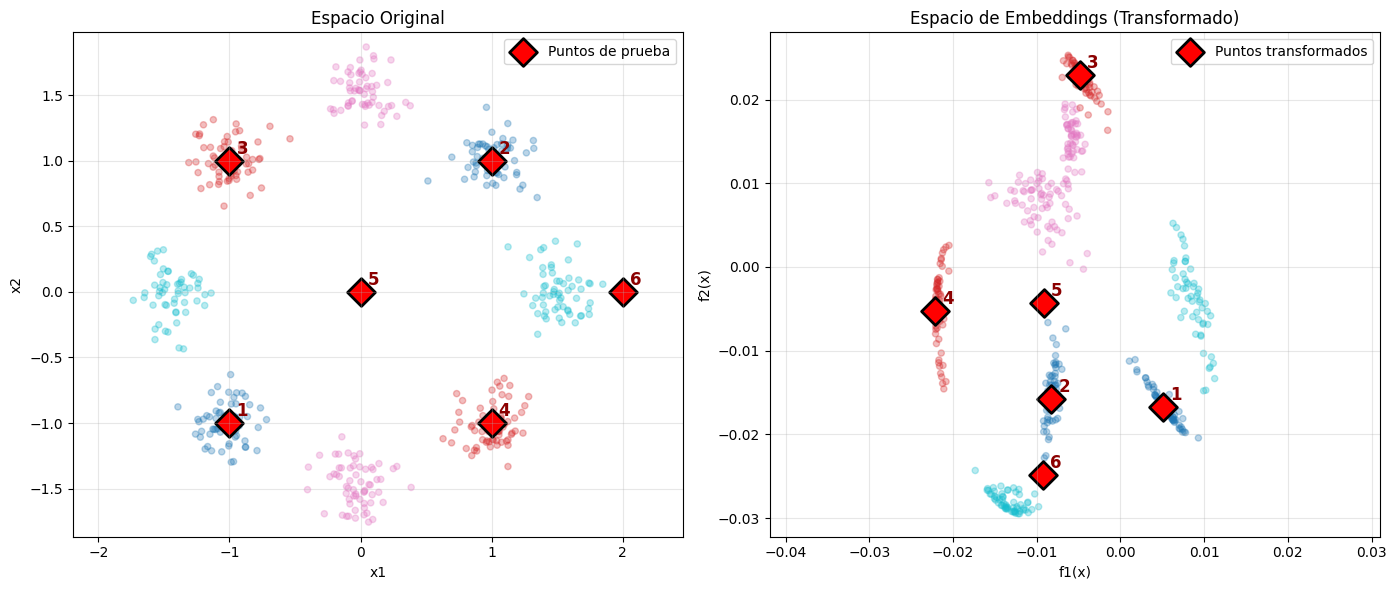

In [49]:
# 19. VISUALIZAR TRANSFORMACIÓN DE PUNTOS DE PRUEBA

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Espacio original con puntos de prueba
ax1 = axes[0]
ax1.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='tab10', s=20, alpha=0.3)
ax1.scatter(puntos_prueba[:,0], puntos_prueba[:,1],
           c='red', s=200, marker='D',
           edgecolors='black', linewidths=2,
           label='Puntos de prueba')
# Etiquetar puntos
for i, p in enumerate(puntos_prueba):
    ax1.annotate(f'{i+1}', (p[0], p[1]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=12, fontweight='bold', color='darkred')
ax1.set_title('Espacio Original')
ax1.set_xlabel('x1')
ax1.set_ylabel('x2')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.axis('equal')

# Espacio de embeddings con puntos transformados
ax2 = axes[1]
ax2.scatter(emb_train[:,0], emb_train[:,1], c=y_train, cmap='tab10', s=20, alpha=0.3)
ax2.scatter(embeddings_prueba[:,0], embeddings_prueba[:,1],
           c='red', s=200, marker='D',
           edgecolors='black', linewidths=2,
           label='Puntos transformados')
# Etiquetar puntos transformados
for i, emb in enumerate(embeddings_prueba):
    ax2.annotate(f'{i+1}', (emb[0], emb[1]),
                xytext=(5, 5), textcoords='offset points',
                fontsize=12, fontweight='bold', color='darkred')
ax2.set_title('Espacio de Embeddings (Transformado)')
ax2.set_xlabel('f1(x)')
ax2.set_ylabel('f2(x)')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.axis('equal')

plt.tight_layout()
plt.show()

In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
ruta = "/content/drive/MyDrive/GaborFeatures_Dictionary25003000.pkl"

In [52]:
import pickle

with open("/content/drive/MyDrive/GaborFeatures_Dictionary25003000.pkl", "rb") as f:
    datos = pickle.load(f)

In [53]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [54]:
import pickle

ruta = '/content/drive/MyDrive/GaborFeatures_Dictionary003000.pkl'

with open(ruta, 'rb') as f:
    data = pickle.load(f)

print(type(data))

<class 'dict'>


In [55]:
print("Tipo de objeto:", type(data))

if isinstance(data, dict):
    print("Número de elementos:", len(data))
    print("Primeras claves:", list(data.keys())[:10])

elif isinstance(data, (list, tuple)):
    print("Número de elementos:", len(data))
    print("Primeros elementos:", data[:5])

else:
    print(data)

Tipo de objeto: <class 'dict'>
Número de elementos: 3000
Primeras claves: ['AA_1.jpg', 'AA_10.jpg', 'AA_11.jpg', 'AA_12.jpg', 'AA_13.jpg', 'AA_14.jpg', 'AA_15.jpg', 'AA_16.jpg', 'AA_17.jpg', 'AA_18.jpg']


In [56]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

display(df.head())
print("Dimensiones:", df.shape)

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,66.511676,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,60.695156,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,65.842245,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,70.937716,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,70.284450,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 24)


In [57]:
import pandas as pd

df = pd.DataFrame.from_dict(data, orient='index')

df = df.reset_index()
df = df.rename(columns={'index': 'ID'})

display(df.head())
print("Dimensiones:", df.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


Dimensiones: (3000, 25)


In [58]:

# 1. Extraer la clave de los dos primeros caracteres de ID
df['clave'] = df['ID'].str[:2]

# 2. Contar cuántas filas tiene cada clave
conteo = df['clave'].value_counts()

# Conservar únicamente las claves con al menos 5 filas
claves_validas = conteo[conteo >= 5].index

# 3. Filtrar y seleccionar las primeras 5 filas de cada clave
df_filtrado = (
    df[df['clave'].isin(claves_validas)]
    .groupby('clave', sort=False)
    .head(5)
    .drop(columns=['clave'])
    .reset_index(drop=True)
)

# Mostrar resultados
display(df_filtrado.head(10))
print("Dimensiones originales:", df.shape)
print("Dimensiones filtradas:", df_filtrado.shape)
print("Claves conservadas:", df_filtrado['ID'].str[:2].nunique())


,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA_1.jpg,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA_10.jpg,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA_11.jpg,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA_12.jpg,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA_13.jpg,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AB_1.jpg,105.117916,102.095392,46.483915,42.552042,239.673632,201.546194,45.379295,56.376756,71.234917,...,19.059347,28.189023,51.112786,103.906695,3.877829,4.191462,167.781034,158.573236,3.620044,3.845175
6,AB_10.jpg,126.052351,125.448270,35.930696,29.857848,241.850214,190.219139,41.440718,56.201264,85.369831,...,15.141034,16.294566,57.998577,101.224474,4.035224,3.444502,168.344632,158.507008,4.998338,6.797159
7,AB_11.jpg,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
8,AB_12.jpg,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
9,AB_13.jpg,108.578149,79.543745,46.442995,33.582344,240.303895,180.146626,54.099140,42.824756,76.844158,...,21.904374,21.576059,56.718997,101.652734,5.044761,4.627593,169.488883,158.964415,4.337753,3.524231


Dimensiones originales: (3000, 26)
Dimensiones filtradas: (810, 25)
Claves conservadas: 162


In [59]:
# Crear una copia del DataFrame filtrado
DATOS = df_filtrado.copy()

# Reemplazar ID por los dos primeros caracteres
DATOS['ID'] = DATOS['ID'].str[:2]

# Mostrar resultados
display(DATOS.head(10))
print("Dimensiones de DATOS:", DATOS.shape)

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209
5,AB,105.117916,102.095392,46.483915,42.552042,239.673632,201.546194,45.379295,56.376756,71.234917,...,19.059347,28.189023,51.112786,103.906695,3.877829,4.191462,167.781034,158.573236,3.620044,3.845175
6,AB,126.052351,125.448270,35.930696,29.857848,241.850214,190.219139,41.440718,56.201264,85.369831,...,15.141034,16.294566,57.998577,101.224474,4.035224,3.444502,168.344632,158.507008,4.998338,6.797159
7,AB,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
8,AB,118.954225,107.219633,47.446928,32.402182,218.248877,173.700994,47.552121,37.217792,75.761158,...,22.254759,19.276253,55.477445,97.292484,4.735450,3.508327,169.167497,158.701916,4.781611,2.991578
9,AB,108.578149,79.543745,46.442995,33.582344,240.303895,180.146626,54.099140,42.824756,76.844158,...,21.904374,21.576059,56.718997,101.652734,5.044761,4.627593,169.488883,158.964415,4.337753,3.524231


Dimensiones de DATOS: (810, 25)


In [60]:
DATOS=DATOS.head(160)
DATOS.shape

(160, 25)

In [61]:
DATOS.head()

,ID,0,1,2,3,4,5,6,7,8,...,14,15,16,17,18,19,20,21,22,23
0,AA,98.587802,86.745731,56.358585,36.834396,197.608060,136.276753,52.395570,32.062011,65.348715,...,20.552723,13.481989,71.452360,104.233713,8.401132,4.834997,170.172671,159.762891,7.858873,5.182043
1,AA,88.966905,84.193557,51.564241,39.888123,187.393759,141.326698,47.304950,32.308756,53.909220,...,18.268532,12.619065,59.123453,100.058671,5.869432,3.970952,170.338179,159.495509,5.131338,3.393768
2,AA,91.252315,91.830931,47.130514,40.372304,194.325836,149.540178,51.444049,36.339900,55.269524,...,15.559509,13.159775,57.505157,101.307417,5.777942,4.010542,169.262009,159.190330,5.283858,3.440455
3,AA,96.639765,104.209909,47.630940,37.634061,196.893628,149.292290,53.426817,36.046112,60.193631,...,22.916943,18.148518,57.757103,101.112273,6.612139,4.460182,169.867327,160.142545,5.566534,4.599890
4,AA,89.947971,92.995640,50.414484,39.064229,189.015450,147.932514,40.398781,27.612294,54.657868,...,19.119533,16.849820,52.958874,100.838511,4.504610,3.778899,168.950984,158.805548,5.306167,4.453209


[AVISO] No se encontró DATOS; usando datos sintéticos.
Muestras totales: 320
Identidades totales: 64
Forma de X: (320, 24)
Cliente 1: 8 identidades, 40 muestras
Cliente 2: 8 identidades, 40 muestras
Cliente 3: 8 identidades, 40 muestras
Cliente 4: 8 identidades, 40 muestras
Cliente 5: 8 identidades, 40 muestras
Cliente 6: 8 identidades, 40 muestras
Cliente 7: 8 identidades, 40 muestras
Cliente 8: 8 identidades, 40 muestras
W: (8, 12)
mu: (12, 24)
log_gamma: (12,)
gamma inicial: 0.009262041832104148

Verificación de gradientes:
  gradcheck W          error relativo máx: 1.68e-08
  gradcheck mu         error relativo máx: 2.94e-06
  gradcheck log_gamma  error relativo máx: 2.77e-07

Pérdida global inicial: 0.882044
Ronda   1/250 | pérdida local media = 0.8774 | pérdida global = 0.8759 | min/max local = 0.820/0.920
Ronda  10/250 | pérdida local media = 0.8058 | pérdida global = 0.7993 | min/max local = 0.701/0.869
Ronda  20/250 | pérdida local media = 0.6842 | pérdida global = 0.6670 | mi

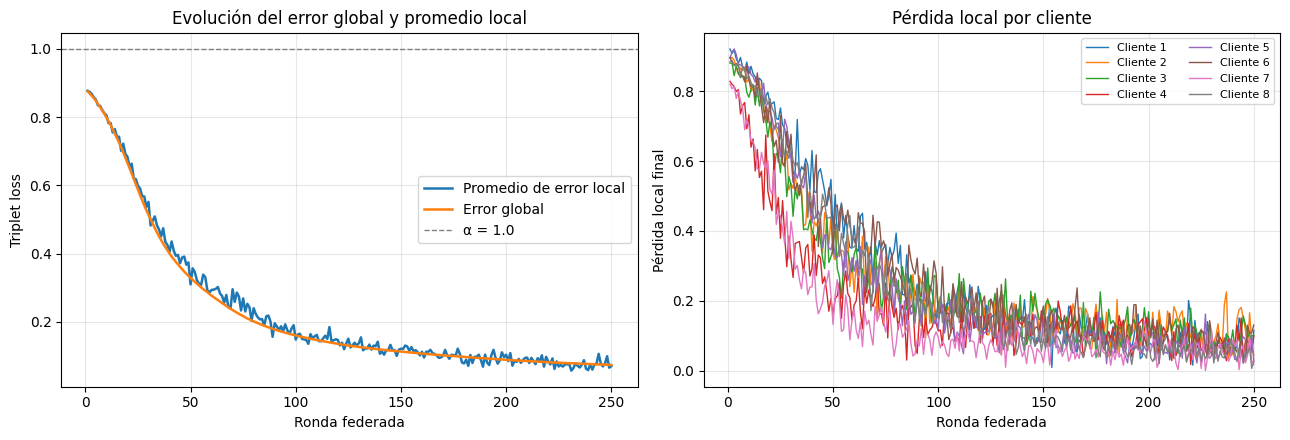

In [62]:
import copy
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CONFIGURACIÓN
CSV_PATH = "DATOS"
D = 24                     # características de entrada
K = 12                     # centros RBF
d = 8                      # dimensión del embedding
NUM_CLIENTS = 8
SAMPLES_PER_IDENTITY = 5
ROUNDS = 250
LOCAL_EPOCHS = 2
BATCH_SIZE = 8
ALPHA = 1.0                # margen de la triplet loss
RANDOM_SEED = 2026

# Tasas de aprendizaje por parámetro (mu y log_gamma son más sensibles)
LR = {"W": 0.05, "mu": 0.01, "log_gamma": 0.01}
CLIP_NORM = 5.0            # recorte de gradiente por parámetro

# CARGA DE DATOS
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    id_col = df.columns[0]
    assert df.shape[1] >= D + 1, f"Se esperaban al menos {D} características."
    feature_cols = list(df.columns[1:D + 1])
    identity_ids = df[id_col].to_numpy()
    X = df[feature_cols].to_numpy(dtype=np.float64)
else:
    # Datos sintéticos SOLO para probar el código si no existe el CSV
    print(f"[AVISO] No se encontró {CSV_PATH}; usando datos sintéticos.")
    _rng = np.random.default_rng(0)
    n_id = 64
    centers = _rng.normal(0, 3.0, size=(n_id, D))
    scales = _rng.uniform(0.3, 1.0, size=n_id)
    identity_ids = np.repeat(np.arange(n_id), SAMPLES_PER_IDENTITY)
    X = centers[identity_ids] + _rng.normal(
        0, 1, size=(len(identity_ids), D)) * scales[identity_ids, None]
df=DATOS
assert X.shape[1] == D
assert np.isfinite(X).all(), "Hay valores NaN o infinitos."
print("Muestras totales:", len(X))
print("Identidades totales:", len(np.unique(identity_ids)))
print("Forma de X:", X.shape)


# PARTICIÓN FEDERADA POR IDENTIDAD
def split_clients_by_identity(X, identity_ids, num_clients,
                              samples_per_identity=5, seed=2026):
    rng = np.random.default_rng(seed)          # ahora sí usa la semilla
    unique_ids = np.unique(identity_ids)

    for identity in unique_ids:
        count = np.sum(identity_ids == identity)
        if count != samples_per_identity:
            raise ValueError(
                f"La identidad {identity} tiene {count} muestras; "
                f"se esperaban {samples_per_identity}.")

    if len(unique_ids) % num_clients != 0:
        raise ValueError("Las identidades deben ser divisibles entre clientes.")

    shuffled = rng.permutation(unique_ids)
    clients = []
    for client_ids in np.array_split(shuffled, num_clients):
        mask = np.isin(identity_ids, client_ids)
        clients.append({"X": X[mask].copy(),
                        "ids": identity_ids[mask],
                        "N_i": len(client_ids)})
    return clients


clients = split_clients_by_identity(
    X, identity_ids, NUM_CLIENTS,
    samples_per_identity=SAMPLES_PER_IDENTITY, seed=RANDOM_SEED)


# ESTANDARIZACIÓN FEDERADA
# Cada cliente envía solo (n, suma, suma de cuadrados).
def federated_standardization(clients):
    n = sum(len(c["X"]) for c in clients)
    s = sum(c["X"].sum(axis=0) for c in clients)
    ss = sum((c["X"] ** 2).sum(axis=0) for c in clients)
    mean = s / n
    std = np.sqrt(np.maximum(ss / n - mean ** 2, 1e-12))
    return mean, std


feat_mean, feat_std = federated_standardization(clients)
for c in clients:
    c["X"] = (c["X"] - feat_mean) / feat_std

for i, c in enumerate(clients):
    print(f"Cliente {i + 1}: {c['N_i']} identidades, {len(c['X'])} muestras")


# INICIALIZACIÓN DEL MODELO
# Centros tomados de TODOS los clientes (no solo del primero)
# y gamma con la heurística de la mediana.
def initialize_parameters(clients, K, d, seed=2026):
    rng = np.random.default_rng(seed)
    C = len(clients)

    # Cada cliente aporta K//C centros (los primeros, uno extra si sobran)
    centers = []
    for i, c in enumerate(clients):
        k_i = K // C + (1 if i < K % C else 0)
        if k_i > 0:
            sel = rng.choice(len(c["X"]), size=k_i, replace=False)
            centers.append(c["X"][sel])
    mu = np.vstack(centers).copy()                       # (K, D)

    # gamma = 1 / (2 * mediana(||mu_i - mu_j||^2))
    diff = mu[:, None, :] - mu[None, :, :]
    r2 = np.sum(diff ** 2, axis=2)
    med = np.median(r2[np.triu_indices(K, k=1)])
    gamma0 = 1.0 / (2.0 * med)

    W = rng.normal(0.0, 1.0 / np.sqrt(K), size=(d, K))   # (d, K)
    log_gamma = np.full(K, np.log(gamma0))               # (K,)

    # Nota: se elimina el sesgo b. La triplet loss depende solo de
    # diferencias entre embeddings, así que su gradiente siempre es 0.
    return {"W": W, "mu": mu, "log_gamma": log_gamma}


theta_global = initialize_parameters(clients, K, d, seed=RANDOM_SEED)
for name, p in theta_global.items():
    print(f"{name}: {p.shape}")
print("gamma inicial:", float(np.exp(theta_global["log_gamma"][0])))


# TRANSFORMACIÓN RBF
def rbf_features(X, mu, gamma):
    diff = X[:, None, :] - mu[None, :, :]                # (B, K, D)
    r2 = np.sum(diff ** 2, axis=2)                       # (B, K)
    return np.exp(-r2 * gamma[None, :]), diff, r2


def transform(X, theta):
    gamma = np.exp(theta["log_gamma"])
    Phi, _, _ = rbf_features(X, theta["mu"], gamma)
    return Phi @ theta["W"].T


# TRIPLETAS
def build_triplets(X, ids, rng):
    """Una tripleta por ancla: positivo misma identidad, negativo distinta."""
    uniq = np.unique(ids)
    if len(uniq) < 2:
        raise ValueError("Se necesitan al menos dos identidades por cliente.")
    groups = {u: np.flatnonzero(ids == u) for u in uniq}

    M = len(X)
    pos = np.empty(M, dtype=int)
    neg = np.empty(M, dtype=int)
    for a in range(M):
        aid = ids[a]
        cand_p = groups[aid][groups[aid] != a]
        pos[a] = rng.choice(cand_p)
        neg_id = rng.choice(uniq[uniq != aid])
        neg[a] = rng.choice(groups[neg_id])
    return X[np.arange(M)], X[pos], X[neg]


# TRIPLET LOSS + GRADIENTES ANALÍTICOS
def triplet_loss_and_gradients(theta, A, P, N, alpha):
    W, mu = theta["W"], theta["mu"]
    gamma = np.exp(theta["log_gamma"])
    B = len(A)
    if B == 0:
        raise ValueError("El minibatch está vacío.")

    Phi_a, diff_a, r2_a = rbf_features(A, mu, gamma)
    Phi_p, diff_p, r2_p = rbf_features(P, mu, gamma)
    Phi_n, diff_n, r2_n = rbf_features(N, mu, gamma)

    Za, Zp, Zn = Phi_a @ W.T, Phi_p @ W.T, Phi_n @ W.T

    d_ap_vec = Za - Zp
    d_an_vec = Za - Zn
    margins = np.sum(d_ap_vec ** 2, axis=1) - np.sum(d_an_vec ** 2, axis=1) + alpha
    active = (margins > 0).astype(np.float64)[:, None]
    loss = float(np.mean(np.maximum(0.0, margins)))

    # Gradientes respecto de los embeddings
    gZa = 2.0 * (Zn - Zp) * active / B
    gZp = -2.0 * d_ap_vec * active / B
    gZn = 2.0 * d_an_vec * active / B

    grad_W = gZa.T @ Phi_a + gZp.T @ Phi_p + gZn.T @ Phi_n

    gPhi_a, gPhi_p, gPhi_n = gZa @ W, gZp @ W, gZn @ W

    # dPhi/dmu = 2 * gamma * Phi * (x - mu)
    def g_mu(gPhi, Phi, diff):
        coef = gPhi * Phi * 2.0 * gamma[None, :]         # (B, K)
        return np.einsum("bk,bkd->kd", coef, diff)

    grad_mu = g_mu(gPhi_a, Phi_a, diff_a) + g_mu(gPhi_p, Phi_p, diff_p) \
        + g_mu(gPhi_n, Phi_n, diff_n)

    # dPhi/dgamma = -r2 * Phi ; d gamma / d log_gamma = gamma
    def g_lg(gPhi, Phi, r2):
        return np.sum(-gPhi * r2 * Phi, axis=0) * gamma

    grad_log_gamma = g_lg(gPhi_a, Phi_a, r2_a) + g_lg(gPhi_p, Phi_p, r2_p) \
        + g_lg(gPhi_n, Phi_n, r2_n)

    return loss, {"W": grad_W, "mu": grad_mu, "log_gamma": grad_log_gamma}


def triplet_loss(theta, A, P, N, alpha):
    Za, Zp, Zn = transform(A, theta), transform(P, theta), transform(N, theta)
    d_ap = np.sum((Za - Zp) ** 2, axis=1)
    d_an = np.sum((Za - Zn) ** 2, axis=1)
    return float(np.mean(np.maximum(0.0, d_ap - d_an + alpha)))


def gradient_check(theta, A, P, N, alpha, eps=1e-6):
    """Compara gradientes analíticos contra diferencias finitas."""
    _, grads = triplet_loss_and_gradients(theta, A, P, N, alpha)
    rng = np.random.default_rng(0)
    for key in theta:
        flat = theta[key].ravel()
        idxs = rng.choice(flat.size, size=min(5, flat.size), replace=False)
        errs = []
        for j in idxs:
            th_p, th_m = copy.deepcopy(theta), copy.deepcopy(theta)
            th_p[key].ravel()[j] += eps
            th_m[key].ravel()[j] -= eps
            num = (triplet_loss(th_p, A, P, N, alpha)
                   - triplet_loss(th_m, A, P, N, alpha)) / (2 * eps)
            ana = grads[key].ravel()[j]
            errs.append(abs(num - ana) / (abs(num) + abs(ana) + 1e-12))
        print(f"  gradcheck {key:10s} error relativo máx: {max(errs):.2e}")


# Verificación de gradientes en un lote de prueba
_rng_chk = np.random.default_rng(RANDOM_SEED)
_A, _P, _N = build_triplets(clients[0]["X"], clients[0]["ids"], _rng_chk)
print("\nVerificación de gradientes:")
gradient_check(theta_global, _A, _P, _N, ALPHA)


# SGD LOCAL
def sgd_update(theta, grads, lr):
    for key in theta:
        g = grads[key]
        norm = np.linalg.norm(g)
        if norm > CLIP_NORM:
            g = g * (CLIP_NORM / norm)
        theta[key] -= lr[key] * g
    return theta


def train_local(theta_global, X_i, ids_i, epochs, batch_size, lr, alpha, seed):
    rng = np.random.default_rng(seed)
    theta_local = copy.deepcopy(theta_global)
    epoch_losses = []

    for _ in range(epochs):
        # Tripletas nuevas en cada época (más variedad de negativos)
        A, P, N = build_triplets(X_i, ids_i, rng)
        perm = rng.permutation(len(A))
        batch_losses = []
        for start in range(0, len(A), batch_size):
            idx = perm[start:start + batch_size]
            loss, grads = triplet_loss_and_gradients(
                theta_local, A[idx], P[idx], N[idx], alpha)
            theta_local = sgd_update(theta_local, grads, lr)
            batch_losses.append(loss)
        epoch_losses.append(float(np.mean(batch_losses)))

    return theta_local, epoch_losses



# FEDAVG (ponderado por número de muestras)

def fedavg(local_parameters, weights):
    w = np.asarray(weights, dtype=np.float64)
    w = w / w.sum()
    return {key: sum(wi * th[key] for wi, th in zip(w, local_parameters))
            for key in local_parameters[0]}


# PÉRDIDA GLOBAL: modelo global evaluado en tripletas fijas de todos los clientes

eval_rng = np.random.default_rng(RANDOM_SEED + 999)
eval_triplets = [build_triplets(c["X"], c["ids"], eval_rng) for c in clients]


def global_loss(theta):
    losses = [triplet_loss(theta, A, P, N, ALPHA) for A, P, N in eval_triplets]
    weights = [len(c["X"]) for c in clients]
    return float(np.average(losses, weights=weights))


# ENTRENAMIENTO FEDERADO

history = {"round": [], "global_loss": [], "mean_local_loss": [],
           "client_losses": []}
init_loss = global_loss(theta_global)
print(f"\nPérdida global inicial: {init_loss:.6f}")

for t in range(ROUNDS):
    local_parameters, round_losses = [], []

    for i, client in enumerate(clients):
        theta_local, losses = train_local(
            theta_global, client["X"], client["ids"],
            epochs=LOCAL_EPOCHS, batch_size=BATCH_SIZE, lr=LR, alpha=ALPHA,
            seed=RANDOM_SEED + t * NUM_CLIENTS + i)
        local_parameters.append(theta_local)
        round_losses.append(losses[-1])

    theta_global = fedavg(local_parameters, [len(c["X"]) for c in clients])

    g_loss = global_loss(theta_global)
    history["round"].append(t + 1)
    history["global_loss"].append(g_loss)
    history["mean_local_loss"].append(float(np.mean(round_losses)))
    history["client_losses"].append(round_losses)

    if (t + 1) % 10 == 0 or t == 0:
        print(f"Ronda {t + 1:3d}/{ROUNDS} | "
              f"pérdida local media = {history['mean_local_loss'][-1]:.4f} | "
              f"pérdida global = {g_loss:.4f} | "
              f"min/max local = {min(round_losses):.3f}/{max(round_losses):.3f}")

theta_final = copy.deepcopy(theta_global)
print("\nEntrenamiento federado terminado.")
for k, v in theta_final.items():
    print(f"{k}: {v.shape}")

# GRÁFICA
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["round"], history["mean_local_loss"],
             label="Promedio de error local", lw=1.8)
axes[0].plot(history["round"], history["global_loss"],
             label="Error global", lw=1.8)
axes[0].axhline(ALPHA, color="gray", ls="--", lw=1, label=f"α = {ALPHA}")
axes[0].set_xlabel("Ronda federada")
axes[0].set_ylabel("Triplet loss")
axes[0].set_title("Evolución del error global y promedio local")
axes[0].legend()
axes[0].grid(alpha=0.3)

cl = np.array(history["client_losses"])
for i in range(NUM_CLIENTS):
    axes[1].plot(history["round"], cl[:, i], lw=1, label=f"Cliente {i + 1}")
axes[1].set_xlabel("Ronda federada")
axes[1].set_ylabel("Pérdida local final")
axes[1].set_title("Pérdida local por cliente")
axes[1].legend(ncol=2, fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("evolucion_error.png", dpi=150)
plt.show()

64 identidades, 5 puntos cada una (verificado).


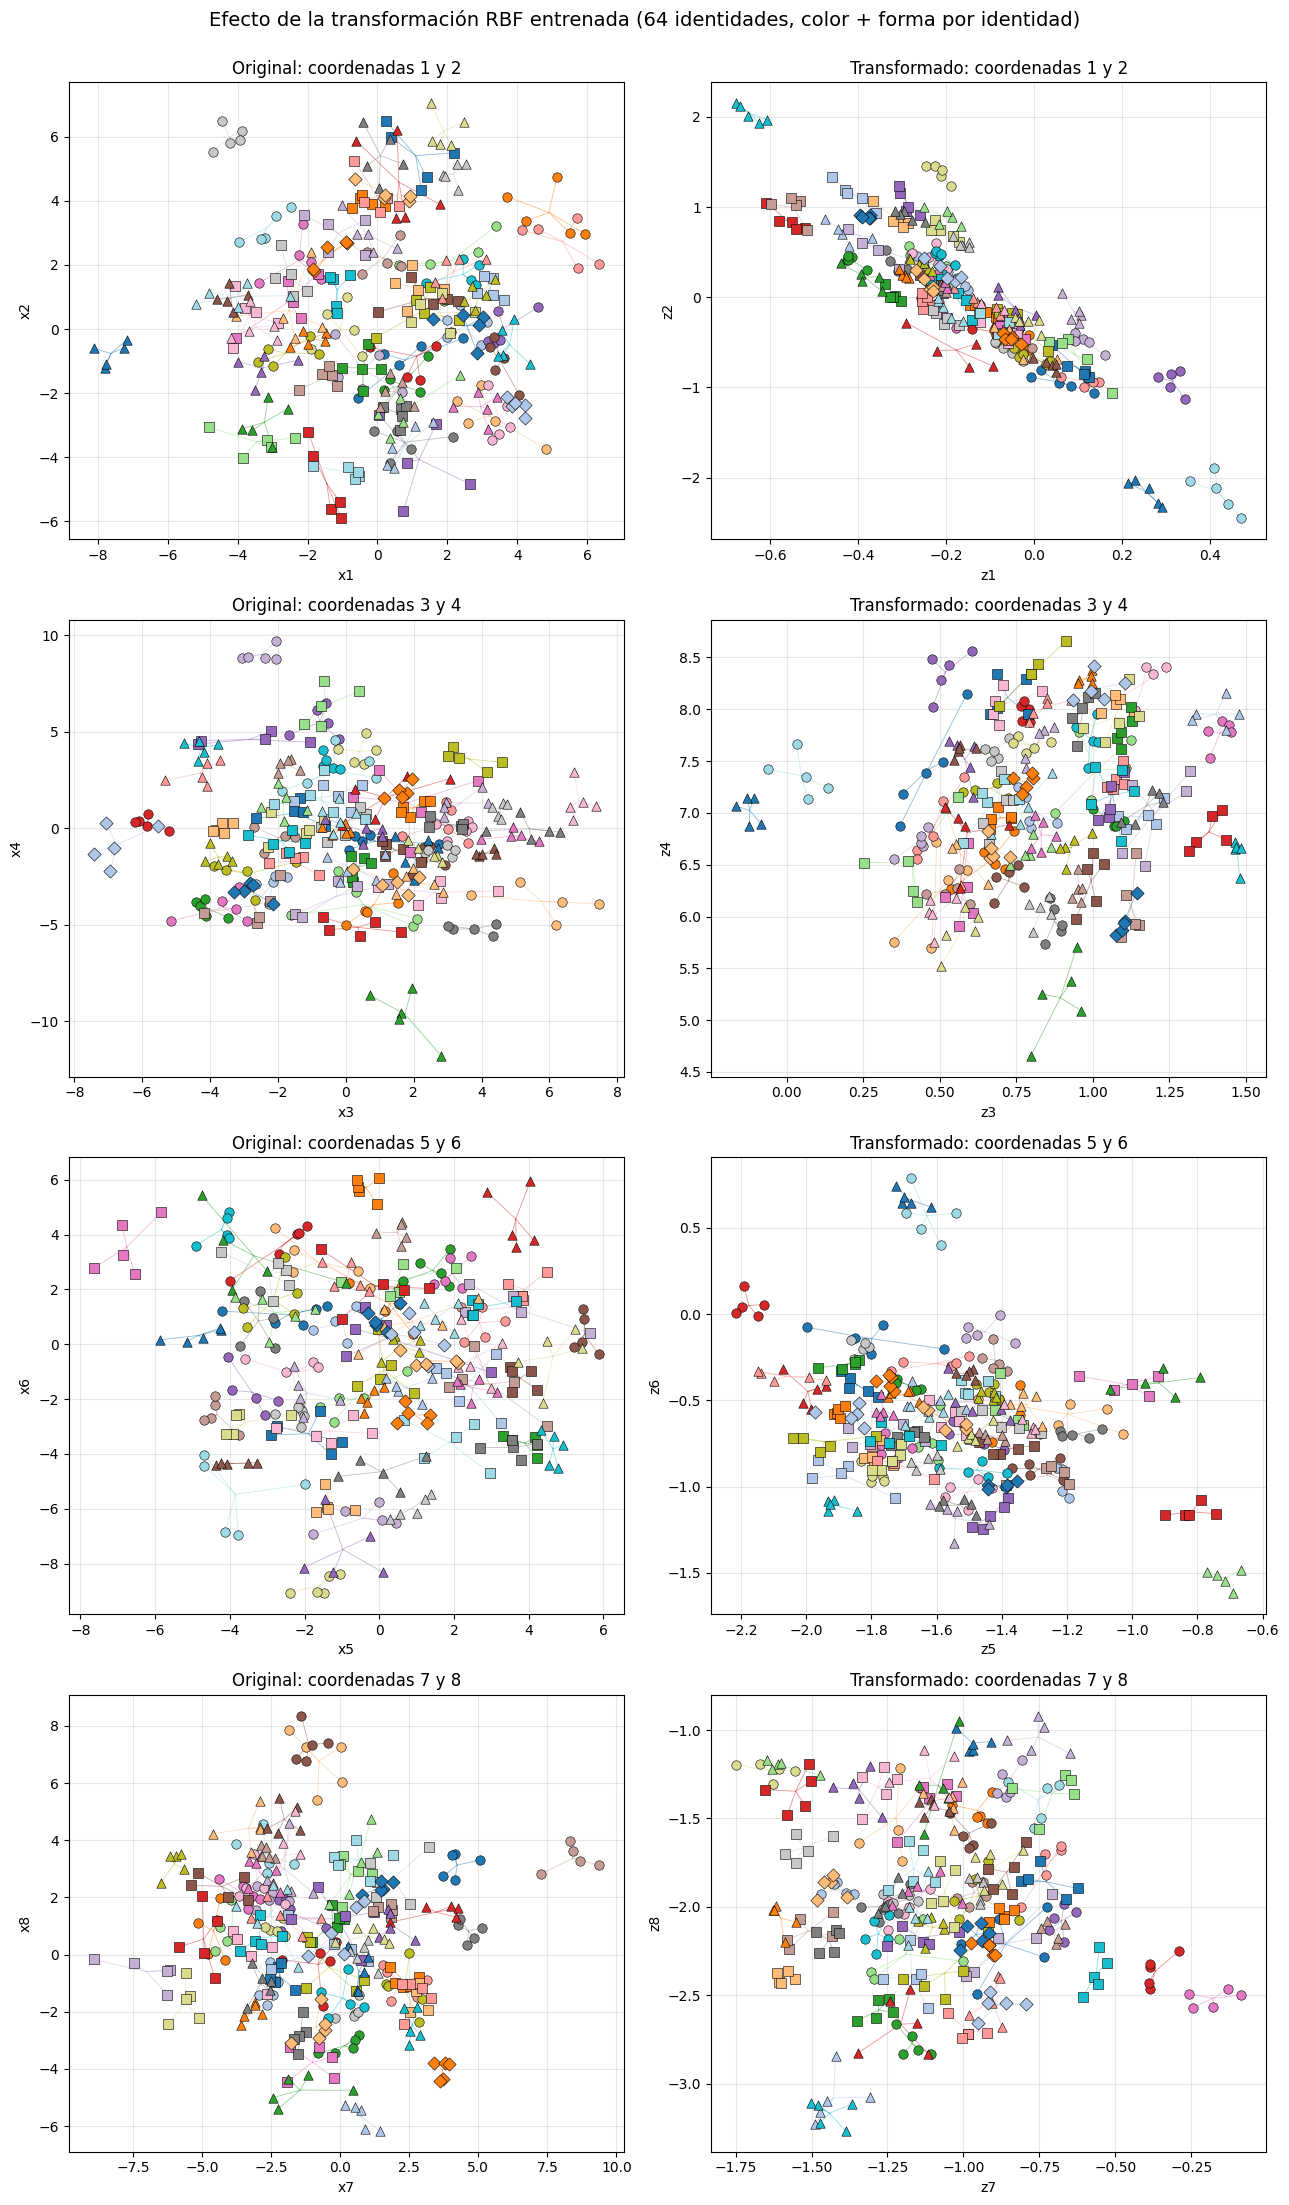

Razón inter/intra (original estandarizado): 4.475
Razón inter/intra (embedding entrenado):   4.821


In [63]:
# VISUALIZACIÓN: ORIGINAL vs TRANSFORMADO
# (ejecutar DESPUÉS del entrenamiento; usa X, identity_ids,
#  feat_mean, feat_std, theta_global/theta_final y transform)
import numpy as np
import matplotlib.pyplot as plt

# Datos originales (sin estandarizar) y su versión transformada
X_orig = X                                              # (320, 24) originales
X_std = (X_orig - feat_mean) / feat_std                 # misma normalización del entrenamiento
Z_all = transform(X_std, theta_final)                   # (320, d) embeddings

# Cada identidad (clave) = combinación única de COLOR + MARCADOR.
# 20 colores bien contrastados x 4 formas = 80 combinaciones (>= 64 identidades).
unique_ids = np.unique(identity_ids)
n_ids = len(unique_ids)
base_colors = plt.cm.tab20(np.arange(20))
markers = ["o", "s", "^", "D"]
assert n_ids <= len(base_colors) * len(markers), "Hay más identidades que combinaciones."

style = {u: (base_colors[i % 20], markers[i // 20]) for i, u in enumerate(unique_ids)}

# Verificación: cada clave debe tener exactamente SAMPLES_PER_IDENTITY puntos
counts = {u: int(np.sum(identity_ids == u)) for u in unique_ids}
assert all(c == SAMPLES_PER_IDENTITY for c in counts.values()), "Conteo por clave inesperado."
print(f"{n_ids} identidades, {SAMPLES_PER_IDENTITY} puntos cada una (verificado).")

SHOW_CENTROID_LINES = True   # líneas finas de cada punto a su centroide


def scatter_pair(ax, data, i, j, title, xlabel, ylabel):
    for u in unique_ids:
        m = identity_ids == u
        color, marker = style[u]
        pts = data[m][:, [i, j]]
        if SHOW_CENTROID_LINES:
            c = pts.mean(axis=0)
            for p in pts:
                ax.plot([c[0], p[0]], [c[1], p[1]], color=color,
                        lw=0.6, alpha=0.5, zorder=1)
        ax.scatter(pts[:, 0], pts[:, 1], color=color, marker=marker, s=46,
                   edgecolors="k", linewidths=0.4, zorder=2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)


# Pares de coordenadas a comparar (índices base 0): (1,2), (3,4), (5,6), (7,8)
pairs = [(0, 1), (2, 3), (4, 5), (6, 7)]
assert Z_all.shape[1] >= max(max(p) for p in pairs) + 1, "El embedding tiene menos de 8 dimensiones."

fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5.5 * len(pairs)))

for row, (i, j) in enumerate(pairs):
    scatter_pair(axes[row, 0], X_orig, i, j,
                 f"Original: coordenadas {i + 1} y {j + 1}",
                 f"x{i + 1}", f"x{j + 1}")
    scatter_pair(axes[row, 1], Z_all, i, j,
                 f"Transformado: coordenadas {i + 1} y {j + 1}",
                 f"z{i + 1}", f"z{j + 1}")

fig.suptitle(f"Efecto de la transformación RBF entrenada "
             f"({n_ids} identidades, color + forma por identidad)",
             fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig("transformacion_original_vs_embedding.png", dpi=130, bbox_inches="tight")
plt.show()

# ------------------------------------------
# Métrica rápida: ¿se separaron mejor las identidades?
# Razón = distancia media entre identidades distintas /
#         distancia media dentro de la misma identidad
# ------------------------------------------
def separation_ratio(data, ids):
    diff = data[:, None, :] - data[None, :, :]
    dist = np.sqrt(np.sum(diff ** 2, axis=2))
    same = ids[:, None] == ids[None, :]
    off_diag = ~np.eye(len(ids), dtype=bool)
    intra = dist[same & off_diag].mean()
    inter = dist[~same].mean()
    return inter / intra


print(f"Razón inter/intra (original estandarizado): "
      f"{separation_ratio(X_std, identity_ids):.3f}")
print(f"Razón inter/intra (embedding entrenado):   "
      f"{separation_ratio(Z_all, identity_ids):.3f}")